This notebook was generated using AI under general human direction. At the time of generation, the contents have not been comprehensively reviewed by a human analyst.

# TD 12 : Risque de première espèce et risque de seconde espèce

Christelle Gonindard, Matthias Grenié, François Bettega

<div class="alert alert-info" role="alert">

## Objectifs

- Comprendre la différence entre risque de première espèce (α) et risque de seconde espèce (β)
- Approcher empiriquement, par simulation, la signification concrète du risque α
- Observer l'effet du seuil α choisi et du nombre de tests réalisés sur le taux de faux positifs
- Comprendre la notion de puissance statistique (1 - β) et les facteurs qui l'influencent
- Identifier pourquoi la maîtrise de ces deux risques est essentielle en recherche en santé

</div>

---

## 1. Mise en situation

Un laboratoire pharmaceutique teste un nouveau médicament censé réduire la tension artérielle. Un essai clinique est mené sur un groupe de patients hypertendus : on mesure la baisse de pression artérielle systolique (en mmHg) après 3 mois de traitement, puis on réalise un test de Student pour savoir si cette baisse moyenne est significativement différente de 0 (c'est-à-dire si le médicament a un effet réel).

Deux scénarios sont possibles, et dans chacun d'eux, le hasard de l'échantillonnage peut nous tromper :

- **Scénario A** : le médicament n'a en réalité **aucun effet** (H0 est vraie). Si notre test conclut malgré tout à un effet significatif, on commet une **erreur de première espèce** (ou « faux positif ») : on valide à tort un médicament inefficace.
- **Scénario B** : le médicament a en réalité **un effet réel** (H0 est fausse). Si notre test ne parvient pas à détecter cet effet, on commet une **erreur de seconde espèce** (ou « faux négatif ») : on passe à côté d'un traitement qui aurait pu bénéficier aux patients.

Ces deux types d'erreur ne sont jamais totalement évitables : un test statistique, basé sur un échantillon, ne donne jamais une certitude absolue. L'objectif de ce TD est de **rendre concrets ces deux risques** en simulant un grand nombre d'essais cliniques virtuels, pour lesquels on connaît la vérité (puisque c'est nous qui la fixons), et en observant à quelle fréquence le test se trompe.

## Rappel de cours

Lorsqu'on réalise un test d'hypothèse, la décision prise (rejeter H0 ou non) peut être croisée avec la réalité (H0 vraie ou fausse), ce qui donne quatre situations possibles :

| | H0 vraie (pas d'effet réel) | H0 fausse (effet réel) |
|---|---|---|
| **On rejette H0** (test « significatif ») | Erreur de première espèce (faux positif), probabilité **α** | Décision correcte (vrai positif), probabilité **1 - β** (= puissance) |
| **On ne rejette pas H0** (test « non significatif ») | Décision correcte (vrai négatif), probabilité **1 - α** | Erreur de seconde espèce (faux négatif), probabilité **β** |

- Le **risque de première espèce** $\alpha$ est la probabilité de conclure à tort à un effet alors qu'il n'y en a pas. C'est précisément le seuil que l'on fixe nous-mêmes avant de réaliser le test (généralement 5%), et qui sert de référence de comparaison à la p-value : si p-value $< \alpha$, on rejette H0.
- Le **risque de seconde espèce** $\beta$ est la probabilité de ne pas détecter un effet alors qu'il existe réellement. Contrairement à $\alpha$, $\beta$ n'est pas fixé à l'avance : il dépend de l'ampleur réelle de l'effet, de la taille de l'échantillon, de la variabilité des données, et du seuil $\alpha$ choisi.
- La **puissance** du test, $1 - \beta$, est la probabilité de détecter un effet réel quand il existe. C'est elle que l'on cherche à maximiser lors de la conception d'une étude (par exemple, en calculant à l'avance la taille d'échantillon nécessaire).

Dans les sections suivantes, on va **simuler** des milliers d'essais cliniques virtuels pour observer empiriquement ces deux risques, d'abord séparément, puis en les reliant au choix du seuil $\alpha$, au nombre de tests réalisés, à la taille d'échantillon, et à l'ampleur de l'effet.

## 2. Un essai clinique virtuel sous H0 vraie

Simulons un premier essai clinique virtuel dans le **scénario A** : le médicament n'a strictement aucun effet. On simule la baisse de tension artérielle de 30 patients comme un tirage aléatoire dans une loi normale de moyenne 0 (pas d'effet) et d'écart-type 10 mmHg (variabilité individuelle réaliste), puis on réalise un test de Student de comparaison à une moyenne théorique de 0, comme au TD4.

In [12]:
# load-packages
set.seed(4827)

In [13]:
# un-seul-essai-H0-vraie
n = 30
baisse_tension = rnorm(n, mean = 0, sd = 10)

test_unique = t.test(baisse_tension, mu = 0)
test_unique


	One Sample t-test

data:  baisse_tension
t = 0.44667, df = 29, p-value = 0.6584
alternative hypothesis: true mean is not equal to 0
95 percent confidence interval:
 -3.148460  4.907969
sample estimates:
mean of x 
0.8797545 


**Commentaire** : la p-value obtenue (≈ 0.66) est largement supérieure à 5%, on ne rejette donc pas H0 — ce qui est la conclusion correcte, puisqu'on sait (parce qu'on l'a simulé ainsi) qu'il n'y a réellement aucun effet.

Mais relancez cette simulation plusieurs fois (changez la valeur du `set.seed()` ci-dessus, ou enlevez cette ligne) : il arrivera, de temps en temps, que la p-value tombe en dessous de 5% par pur hasard d'échantillonnage, alors même que H0 est vraie. C'est précisément cela, une **erreur de première espèce**. Pour en observer la fréquence exacte, il ne suffit pas de relancer la simulation « à la main » quelques fois : il faut la répéter un grand nombre de fois de façon systématique, ce que l'on fait dans la section suivante.

## 3. Approcher empiriquement le risque α par simulation

### 3.1 Répéter l'essai clinique 10 000 fois sous H0 vraie

On répète maintenant la même expérience 10 000 fois : à chaque répétition, on simule un nouvel échantillon de 30 patients sous l'hypothèse que le médicament n'a aucun effet (H0 vraie), on réalise le test de Student, et on conserve la p-value obtenue. Comme H0 est vraie à chaque répétition par construction, **toute conclusion de rejet de H0 sera une erreur de première espèce**.

In [14]:
# simulation-repetee-H0-vraie
n_simulations = 10000
n_patients = 30

simuler_p_value_H0 = function(n) {
  echantillon = rnorm(n, mean = 0, sd = 10)
  t.test(echantillon, mu = 0)$p.value
}

p_values_H0 = replicate(n_simulations, simuler_p_value_H0(n_patients))

# proportion de tests significatifs au seuil alpha = 5%, alors que H0 est vraie
alpha = 0.05
taux_faux_positifs = mean(p_values_H0 < alpha)
taux_faux_positifs

[1] 0.052

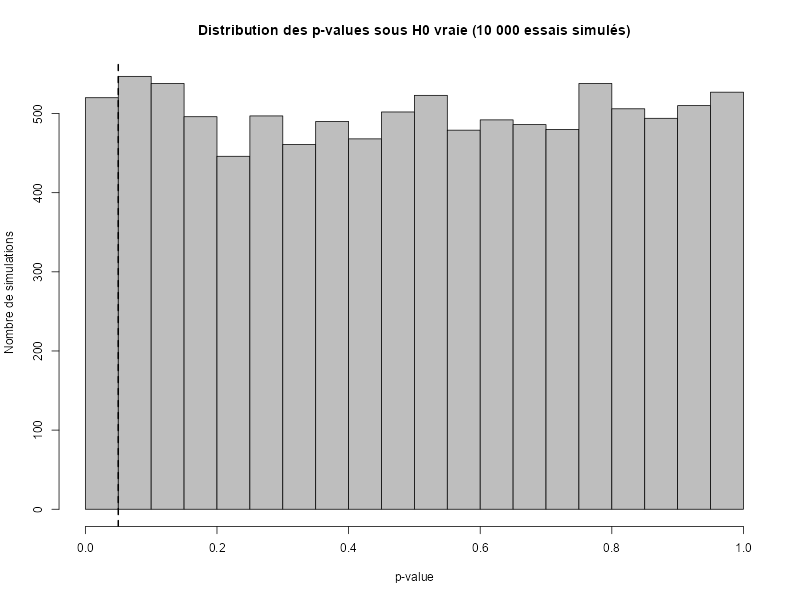

In [15]:
# histogramme-p-values-H0
hist(
  p_values_H0,
  breaks = seq(0, 1, by = 0.05),
  col = "grey",
  xlab = "p-value",
  ylab = "Nombre de simulations",
  main = "Distribution des p-values sous H0 vraie (10 000 essais simulés)"
)
abline(v = alpha, lty = 2, lwd = 2)

**Commentaire** : le taux de faux positifs observé (≈ 5.2%) est très proche du seuil théorique $\alpha = 5\%$ fixé au départ. Ce n'est pas une coïncidence : **sous H0 vraie, la p-value suit une loi uniforme entre 0 et 1**, ce que confirme l'histogramme ci-dessus (les barres ont toutes une hauteur comparable). Par construction, la proportion de valeurs tombant en dessous de n'importe quel seuil $\alpha$ est donc égale à $\alpha$.

Autrement dit : **le risque de première espèce n'est pas un défaut du test, c'est une propriété voulue et calibrée** par le seuil $\alpha$ que l'on choisit avant de réaliser le test. Même avec une procédure parfaitement correcte, appliquée à des données parfaitement conformes à H0, on s'attend à conclure à tort environ 5 fois sur 100 si l'on fixe $\alpha = 5\%$.

### 3.2 Effet du seuil α choisi

Puisque le risque de première espèce est directement fixé par le choix de $\alpha$, on doit pouvoir l'observer en reprenant les mêmes 10 000 p-values simulées ci-dessus, et en comptant le taux de faux positifs pour différents seuils $\alpha$.

In [16]:
# effet-du-seuil-alpha
seuils_alpha = c(0.01, 0.05, 0.10, 0.20)

taux_observes = sapply(seuils_alpha, function(a) mean(p_values_H0 < a))

data.frame(
  alpha_theorique = seuils_alpha,
  taux_faux_positifs_observe = taux_observes
)

  alpha_theorique taux_faux_positifs_observe
1            0.01                     0.0096
2            0.05                     0.0520
3            0.10                     0.1067
4            0.20                     0.2101

**Commentaire** : quel que soit le seuil $\alpha$ choisi (1%, 5%, 10% ou 20%), le taux de faux positifs observé empiriquement lui est très proche. Choisir un $\alpha$ plus strict (par exemple 1% plutôt que 5%) réduit donc mécaniquement le risque de conclure à tort à un effet — mais, comme on le verra en section 4, cela a un coût : cela rend aussi plus difficile de détecter un effet réel lorsqu'il existe (augmentation du risque $\beta$). Choisir $\alpha$ est donc un compromis, pas une formalité administrative.

### 3.3 Le piège des tests multiples

Imaginons maintenant une situation fréquente en recherche biomédicale : plutôt que de tester un seul médicament, un laboratoire teste **20 biomarqueurs sanguins différents** pour savoir s'ils diffèrent entre un groupe de patients malades et un groupe de patients sains — alors qu'en réalité, **aucun des 20 biomarqueurs n'a réellement d'effet** (tous les H0 sont vraies). On réalise donc 20 tests de Student indépendants sur ce même jeu de données, et on regarde combien d'entre eux ressortent « significatifs » au seuil $\alpha = 5\%$ par pur hasard.

In [17]:
# tests-multiples-sans-correction
n_biomarqueurs = 20
n_patients_biomarqueurs = 30

simuler_un_essai_multiple = function(n_tests, n) {
  p_values = replicate(n_tests, simuler_p_value_H0(n))
  any(p_values < alpha)
}

# on répète 5000 fois l'expérience "tester 20 biomarqueurs indépendants, tous sans effet réel"
n_repetitions = 5000
au_moins_un_faux_positif = replicate(
  n_repetitions,
  simuler_un_essai_multiple(n_biomarqueurs, n_patients_biomarqueurs)
)

# proportion d'essais où au moins un des 20 tests est (à tort) déclaré significatif
taux_au_moins_un_faux_positif = mean(au_moins_un_faux_positif)
taux_au_moins_un_faux_positif

[1] 0.6374

In [18]:
# comparaison-formule-theorique
# Formule théorique : si les 20 tests sont indépendants, P(au moins un faux positif) = 1 - (1 - alpha)^20
taux_theorique = 1 - (1 - alpha)^n_biomarqueurs
taux_theorique

[1] 0.6415141

**Commentaire** : alors qu'aucun des 20 biomarqueurs n'a réellement d'effet, on observe empiriquement que dans environ **64% des essais simulés, au moins un des 20 tests ressort significatif par pur hasard** — un résultat cohérent avec la formule théorique $1 - (1-\alpha)^{20} \approx 64\%$. Autrement dit, loin d'être un évènement rare, il est **plus probable qu'improbable** d'obtenir au moins un « faux signal » dès qu'on multiplie les tests sans précaution.

C'est le piège classique des études exploratoires testant de nombreuses variables (biomarqueurs, gènes, régions cérébrales en imagerie...) : si l'on ne corrige pas le seuil de significativité pour tenir compte du nombre de tests réalisés (par exemple avec une correction de Bonferroni, qui consiste à utiliser le seuil $\alpha / 20$ au lieu de $\alpha$ pour chaque test), le risque de publier un résultat qui n'est qu'un artefact du hasard devient très élevé. On retrouve ici, à plus grande échelle, la même logique que lorsqu'on teste plusieurs paires de variables avec le test du $\chi^2$ (TD9-TD10).

## 4. Risque de seconde espèce et puissance statistique

### 4.1 Simuler un effet réel

Changeons maintenant de scénario : le médicament a cette fois **un effet réel**, qui fait baisser la tension artérielle de 4 mmHg en moyenne (H0 est donc fausse). On répète la même procédure que précédemment — simuler un échantillon, réaliser le test, noter la p-value — mais cette fois en simulant les données avec cette moyenne réelle de -4 au lieu de 0. Comme H0 est fausse à chaque répétition, **toute conclusion de non-rejet de H0 sera une erreur de seconde espèce**.

In [19]:
# simulation-repetee-H1-vraie
simuler_p_value_H1 = function(n, effet_reel, sd = 10) {
  echantillon = rnorm(n, mean = effet_reel, sd = sd)
  t.test(echantillon, mu = 0)$p.value
}

p_values_H1 = replicate(
  n_simulations,
  simuler_p_value_H1(n = n_patients, effet_reel = -4)
)

# proportion de tests qui NE détectent PAS l'effet réel, alors qu'il existe : risque beta observé
taux_faux_negatifs = mean(p_values_H1 >= alpha)
taux_faux_negatifs

[1] 0.4303

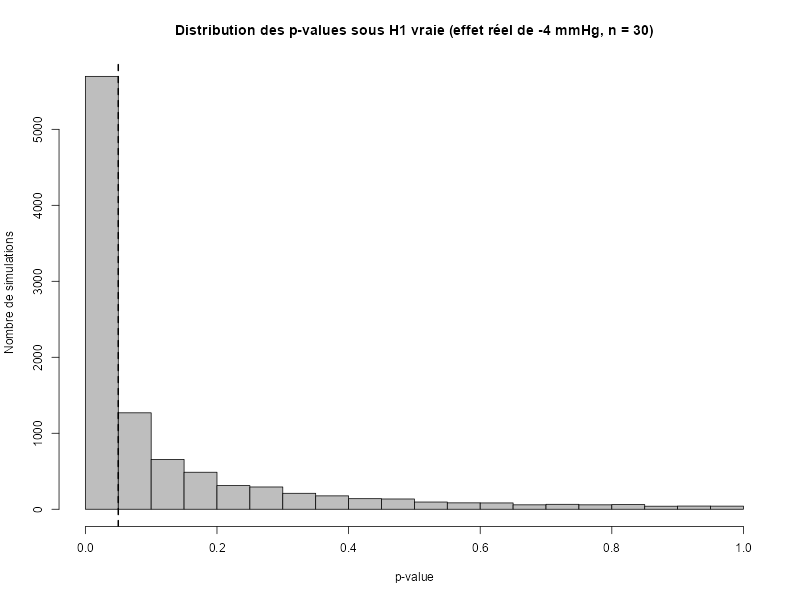

In [20]:
# histogramme-p-values-H1
hist(
  p_values_H1,
  breaks = seq(0, 1, by = 0.05),
  col = "grey",
  xlab = "p-value",
  ylab = "Nombre de simulations",
  main = "Distribution des p-values sous H1 vraie (effet réel de -4 mmHg, n = 30)"
)
abline(v = alpha, lty = 2, lwd = 2)

**Commentaire** : contrairement au cas H0 vraie, la distribution des p-values est maintenant très concentrée près de 0, car le test a tendance à détecter l'effet réel. Mais la concentration est loin d'être totale : environ **43% des essais simulés ne détectent pas l'effet pourtant bien réel** (p-value ≥ 5%, à droite de la ligne pointillée). Ce taux de 43% est une estimation empirique du risque de seconde espèce $\beta$ dans cette configuration précise (effet de -4 mmHg, écart-type de 10, échantillon de 30 patients). La puissance du test, $1 - \beta$, est donc ici d'environ 57% seulement : un essai clinique mené dans ces conditions a presque autant de chances de rater l'effet que de le détecter, alors que le médicament fonctionne réellement.

### 4.2 Qu'est-ce qui influence la puissance ?

La puissance (1 - β) observée ci-dessus n'est pas une propriété fixe du test : elle dépend de la situation étudiée. Deux leviers principaux jouent sur elle :

- la **taille de l'échantillon** $n$ : plus on recrute de patients, plus l'estimation de l'effet est précise, et plus il est facile de distinguer un effet réel (même petit) du bruit d'échantillonnage ;
- l'**ampleur de l'effet réel** : un effet important (par exemple une forte baisse de tension) est plus facile à détecter qu'un effet discret, pour une taille d'échantillon donnée.

On illustre ces deux leviers en faisant varier systématiquement $n$ et l'ampleur de l'effet, et en recalculant à chaque fois la puissance empirique (sur 2000 répétitions par combinaison, pour limiter le temps de calcul).

In [21]:
# puissance-selon-n-et-effet
calculer_puissance_empirique = function(n, effet_reel, n_repet = 2000, sd = 10) {
  p_values = replicate(n_repet, simuler_p_value_H1(n = n, effet_reel = effet_reel, sd = sd))
  mean(p_values < alpha)
}

tailles_echantillon = c(10, 20, 30, 50, 80, 120)
effets_reels = c(-2, -4, -6)

resultats_puissance = expand.grid(
  n = tailles_echantillon,
  effet = effets_reels
)
resultats_puissance$puissance = mapply(
  function(n, effet) calculer_puissance_empirique(n, effet),
  resultats_puissance$n,
  resultats_puissance$effet
)

resultats_puissance

     n effet puissance
1   10    -2    0.0850
2   20    -2    0.1380
3   30    -2    0.1860
4   50    -2    0.2820
5   80    -2    0.4345
6  120    -2    0.5780
7   10    -4    0.2070
8   20    -4    0.3765
9   30    -4    0.5565
10  50    -4    0.8020
11  80    -4    0.9370
12 120    -4    0.9890
13  10    -6    0.4010
14  20    -6    0.7195
15  30    -6    0.8865
16  50    -6    0.9825
17  80    -6    0.9990
18 120    -6    1.0000

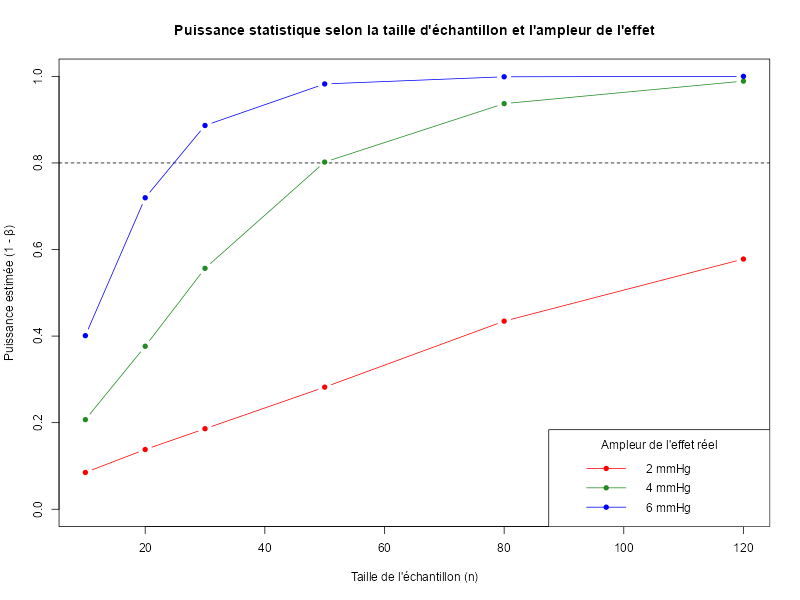

In [22]:
# graphique-puissance-selon-n-et-effet
couleurs = c("red", "forestgreen", "blue")
effets_abs = sort(unique(abs(effets_reels)))

plot(
  NULL,
  xlim = range(tailles_echantillon),
  ylim = c(0, 1),
  xlab = "Taille de l'échantillon (n)",
  ylab = "Puissance estimée (1 - β)",
  main = "Puissance statistique selon la taille d'échantillon et l'ampleur de l'effet"
)
abline(h = 0.80, lty = 2)

for (i in seq_along(effets_abs)) {
  sous_ensemble = resultats_puissance[abs(resultats_puissance$effet) == effets_abs[i], ]
  sous_ensemble = sous_ensemble[order(sous_ensemble$n), ]
  lines(sous_ensemble$n, sous_ensemble$puissance, col = couleurs[i], type = "b", pch = 16)
}

legend(
  "bottomright",
  legend = paste(effets_abs, "mmHg"),
  col = couleurs,
  lty = 1,
  pch = 16,
  title = "Ampleur de l'effet réel"
)

**Commentaire** : les trois courbes illustrent les deux leviers de la puissance :

- à ampleur d'effet fixée (une courbe), la puissance **augmente avec la taille de l'échantillon** : par exemple, pour un effet de 4 mmHg, la puissance passe d'environ 21% à n = 10 à presque 99% à n = 120 ;
- à taille d'échantillon fixée (une valeur de n), la puissance **augmente avec l'ampleur de l'effet réel** : un effet discret de 2 mmHg reste difficile à détecter même avec 120 patients (puissance ≈ 58%), alors qu'un effet de 6 mmHg est quasi systématiquement détecté dès n = 30.

La ligne pointillée horizontale représente le seuil de puissance de 80%, une convention usuelle en recherche clinique : c'est elle qui sert de base au **calcul a priori de la taille d'échantillon nécessaire** avant de lancer un essai, une fois qu'on a choisi un $\alpha$, estimé la variabilité des données, et fixé la plus petite différence que l'on souhaite pouvoir détecter de façon fiable (ce qu'on appelle en pratique une analyse de puissance, réalisable avec la fonction `power.t.test()` en R).

## 5. Pourquoi ces risques comptent particulièrement en santé

<div class="alert alert-success" role="alert">

## En résumé

- Le **risque de première espèce** ($\alpha$) est la probabilité de conclure à tort à un effet qui n'existe pas. C'est un seuil que l'on **choisit** avant le test (généralement 5%), et qui est respecté « à la lettre » même dans la situation la plus défavorable (H0 parfaitement vraie), comme le montre la simulation de la section 3.1.
- Multiplier les tests sans les corriger **gonfle rapidement** le risque global de faux positif : avec 20 tests indépendants et $\alpha = 5\%$ par test, la probabilité d'au moins un faux positif dépasse 60% (section 3.3).
- Le **risque de seconde espèce** ($\beta$) est la probabilité de ne pas détecter un effet qui existe réellement. Il n'est pas fixé à l'avance : il dépend de la taille de l'échantillon, de l'ampleur réelle de l'effet, de la variabilité des données et du seuil $\alpha$ choisi (section 4).
- La **puissance** (1 - β) d'une étude doit être anticipée *avant* de la mener, en estimant la taille d'échantillon nécessaire pour atteindre une puissance suffisante (conventionnellement 80%), étant donné l'effet minimal que l'on souhaite pouvoir détecter.

</div>

En contexte de santé, ces deux risques ne sont pas de simples abstractions mathématiques : ils ont des **conséquences cliniques et éthiques concrètes**, asymétriques selon le type d'erreur :

- **Un faux positif** (erreur de première espèce) peut conduire à mettre sur le marché un traitement inefficace, voire à l'administrer largement à des patients qui en subiront les effets secondaires sans en tirer de bénéfice réel. C'est également un gaspillage de ressources de santé publique, et un signal scientifique trompeur qui peut orienter de futures recherches sur une fausse piste.
- **Un faux négatif** (erreur de seconde espèce) peut conduire à écarter à tort un traitement réellement efficace — en particulier si l'essai clinique était sous-dimensionné (trop peu de patients recrutés) pour avoir une puissance suffisante. Des patients sont alors privés d'un traitement qui aurait pu les aider, et le développement du médicament peut être abandonné alors qu'il était prometteur.

C'est précisément pour cette raison que les protocoles d'essais cliniques (et les comités d'éthique qui les valident) exigent systématiquement un **calcul de taille d'échantillon a priori**, basé sur une puissance cible (le plus souvent 80% ou 90%) : recruter délibérément trop peu de patients expose à un risque élevé de conclure à tort à l'absence d'effet, ce qui est à la fois une perte scientifique et, potentiellement, une perte de chance pour de futurs patients. À l'inverse, fixer un $\alpha$ très permissif (ou tester trop de variables sans correction) revient à abaisser artificiellement la barre de preuve exigée pour qu'un traitement soit déclaré efficace — un risque que la recherche en santé ne peut pas se permettre de prendre à la légère.

**Point clé à retenir** : $\alpha$ et $\beta$ ne sont jamais réductibles à 0 simultanément avec un échantillon de taille fixée — réduire l'un (en durcissant le seuil $\alpha$) tend mécaniquement à augmenter l'autre, à moins d'augmenter la taille de l'échantillon. Choisir ces seuils est donc un **arbitrage scientifique et éthique**, pas un détail technique à appliquer par défaut.